# ETT: 追加3系列の相関ヒートマップ

既存EDAで作成したETTh1のヒートマップに加え、ETTh2・ETTm1・ETTm2についてOTと負荷6系列のPearson相関を計算し、相関行列CSVと注釈付きヒートマップPNGをDriveへ保存します。相関は変数間の関連を示すもので、因果関係を意味しません。

データは既存EDAと同じGoogle Driveの `assignment-main/data` から読み込み、出力は `assignment-main/eda_output` に保存します。

## 1. ライブラリのインポートと描画設定

既存EDAと同じSeabornのテーマ、`vlag`カラーマップ、相関値の範囲を使います。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.colab import drive

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 7)
plt.rcParams["axes.titleweight"] = "bold"

DATA_DIR = Path("/content/drive/Othercomputers/マイ Mac/assignment-main/data")
OUTPUT_DIR = Path("/content/drive/Othercomputers/マイ Mac/assignment-main/eda_output")
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
DATASET_NAMES = ["ETTh2", "ETTm1", "ETTm2"]
SENSOR_COLUMNS = ["OT", "HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL"]
CORRELATION_METHOD = "pearson"  # pearson または spearman

if CORRELATION_METHOD not in {"pearson", "spearman"}:
    raise ValueError("CORRELATION_METHODは'pearson'または'spearman'を指定してください。")

drive.mount("/content/drive")
for directory in (FIGURE_DIR, TABLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("入力フォルダー:", DATA_DIR)
print("出力フォルダー:", OUTPUT_DIR)
print("相関方法:", CORRELATION_METHOD)

Mounted at /content/drive
入力フォルダー: /content/drive/Othercomputers/マイ Mac/assignment-main/data
出力フォルダー: /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output
相関方法: pearson


## 2. 3つの追加データセットの読み込み

ETTh2・ETTm1・ETTm2を既存EDAと同じ固定データフォルダーから読み込みます。各データを名前から参照できる辞書にまとめます。

In [2]:
datasets = {}
for dataset_name in DATASET_NAMES:
    csv_path = DATA_DIR / f"{dataset_name}.csv"
    if not csv_path.is_file():
        raise FileNotFoundError(f"{dataset_name}のCSVが見つかりません: {csv_path}")

    frame = pd.read_csv(csv_path)
    missing_columns = sorted(set(["date"] + SENSOR_COLUMNS) - set(frame.columns))
    if missing_columns:
        raise ValueError(f"{dataset_name}: 必須列がありません: {missing_columns}")

    frame = frame[["date"] + SENSOR_COLUMNS].copy()
    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
    frame = frame.dropna(subset=["date"]).sort_values("date").set_index("date")
    frame[SENSOR_COLUMNS] = frame[SENSOR_COLUMNS].apply(pd.to_numeric, errors="coerce")
    datasets[dataset_name] = frame
    print(f"{dataset_name}: {len(frame):,} rows | {frame.index.min()} -> {frame.index.max()}")

ETTh2: 17,420 rows | 2016-07-01 00:00:00 -> 2018-06-26 19:00:00
ETTm1: 69,680 rows | 2016-07-01 00:00:00 -> 2018-06-26 19:45:00
ETTm2: 69,680 rows | 2016-07-01 00:00:00 -> 2018-06-26 19:45:00


## 3. 相関分析用の前処理

数値列だけを使い、無限値を欠損として扱います。欠損を含む行を除外し、相関が定義できない定数列も取り除きます。

In [3]:
def prepare_numeric_frame(frame, dataset_name):
    numeric = frame.select_dtypes(include=[np.number]).copy()
    numeric = numeric.replace([np.inf, -np.inf], np.nan)
    rows_before = len(numeric)
    numeric = numeric.dropna(axis=0, how="any")
    dropped_rows = rows_before - len(numeric)
    constant_columns = numeric.columns[numeric.nunique(dropna=True) <= 1].tolist()
    numeric = numeric.drop(columns=constant_columns)
    if len(numeric) < 2:
        raise ValueError(f"{dataset_name}: 相関計算に使える行が2件未満です。")
    if numeric.shape[1] < 2:
        raise ValueError(f"{dataset_name}: 定数列除去後に数値列が2列未満です。")
    print(
        f"{dataset_name}: numeric={numeric.shape[1]} columns, "
        f"dropped_rows={dropped_rows}, removed_constant_columns={constant_columns or 'none'}"
    )
    return numeric


prepared_datasets = {
    name: prepare_numeric_frame(frame, name)
    for name, frame in datasets.items()
}

ETTh2: numeric=7 columns, dropped_rows=0, removed_constant_columns=none
ETTm1: numeric=7 columns, dropped_rows=0, removed_constant_columns=none
ETTm2: numeric=7 columns, dropped_rows=0, removed_constant_columns=none


## 4. 相関行列を作成する共通関数

PearsonまたはSpearmanを引数で選べる関数を定義します。前処理後の列数と方式を検証します。

In [4]:
def make_correlation_matrix(frame, method="pearson"):
    if method not in {"pearson", "spearman"}:
        raise ValueError("methodは'pearson'または'spearman'を指定してください。")
    if frame.shape[1] < 2:
        raise ValueError("相関行列には数値列が2列以上必要です。")
    return frame.corr(method=method, min_periods=2)


correlation_matrices = {
    name: make_correlation_matrix(frame, method=CORRELATION_METHOD)
    for name, frame in prepared_datasets.items()
}
for name, matrix in correlation_matrices.items():
    print(name)
    display(matrix.round(3))

ETTh2


,OT,HUFL,HULL,MUFL,MULL,LUFL,LULL
OT,1.000,0.035,0.338,0.194,0.495,-0.144,-0.112
HUFL,0.035,1.000,0.670,0.200,0.527,0.669,0.154
HULL,0.338,0.670,1.000,0.118,0.915,0.595,0.198
MUFL,0.194,0.200,0.118,1.000,0.251,-0.071,-0.600
MULL,0.495,0.527,0.915,0.251,1.000,0.355,0.009
LUFL,-0.144,0.669,0.595,-0.071,0.355,1.000,0.169
LULL,-0.112,0.154,0.198,-0.600,0.009,0.169,1.000


ETTm1


,OT,HUFL,HULL,MUFL,MULL,LUFL,LULL
OT,1.000,0.061,0.225,0.052,0.220,0.120,0.069
HUFL,0.061,1.000,0.117,0.987,0.067,0.299,0.026
HULL,0.225,0.117,1.000,0.070,0.931,0.266,0.380
MUFL,0.052,0.987,0.070,1.000,0.046,0.183,-0.046
MULL,0.220,0.067,0.931,0.046,1.000,0.133,0.071
LUFL,0.120,0.299,0.266,0.183,0.133,1.000,0.342
LULL,0.069,0.026,0.380,-0.046,0.071,0.342,1.000


ETTm2


,OT,HUFL,HULL,MUFL,MULL,LUFL,LULL
OT,1.000,0.034,0.337,0.194,0.495,-0.144,-0.113
HUFL,0.034,1.000,0.671,0.200,0.526,0.669,0.154
HULL,0.337,0.671,1.000,0.117,0.914,0.594,0.200
MUFL,0.194,0.200,0.117,1.000,0.250,-0.070,-0.599
MULL,0.495,0.526,0.914,0.250,1.000,0.354,0.011
LUFL,-0.144,0.669,0.594,-0.070,0.354,1.000,0.168
LULL,-0.113,0.154,0.200,-0.599,0.011,0.168,1.000


## 5. `correlation_heatmap` 描画関数

相関行列、図タイトル、注釈や色範囲などを受け取り、FigureとAxesを返す共通関数を定義します。

In [5]:
def correlation_heatmap(
    correlation_matrix,
    title,
    annot=True,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    cmap="vlag",
    figsize=(9, 7),
):
    if correlation_matrix.shape[0] < 2 or correlation_matrix.shape[1] < 2:
        raise ValueError("ヒートマップには2列以上の相関行列が必要です。")
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        correlation_matrix,
        annot=annot,
        fmt=fmt,
        cmap=cmap,
        center=0,
        vmin=vmin,
        vmax=vmax,
        square=True,
        ax=ax,
    )
    ax.set_title(title)
    fig.tight_layout()
    return fig, ax

## 6. 3データセットのヒートマップ生成

ETTh2・ETTm1・ETTm2ごとに相関行列を描画し、データセット別のFigureとして保持・表示します。

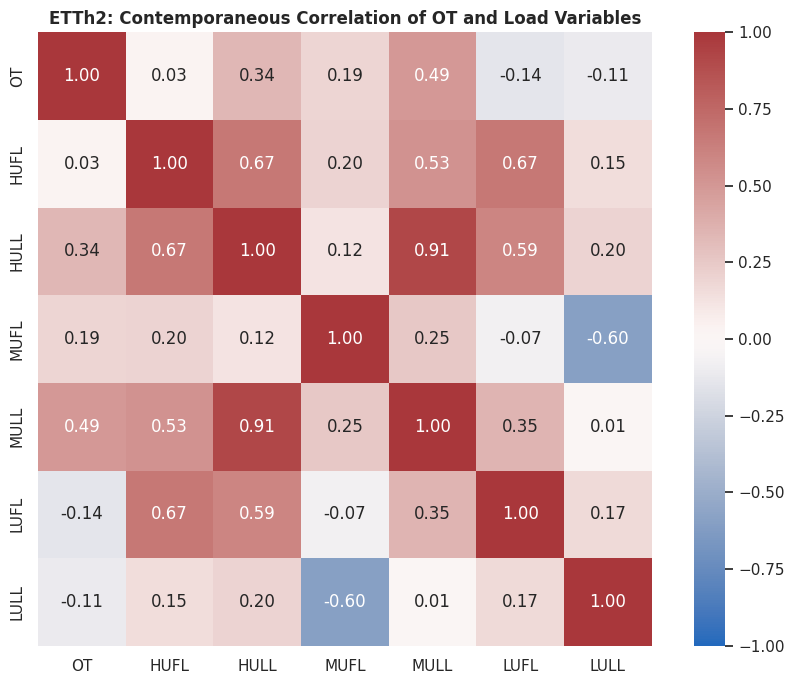

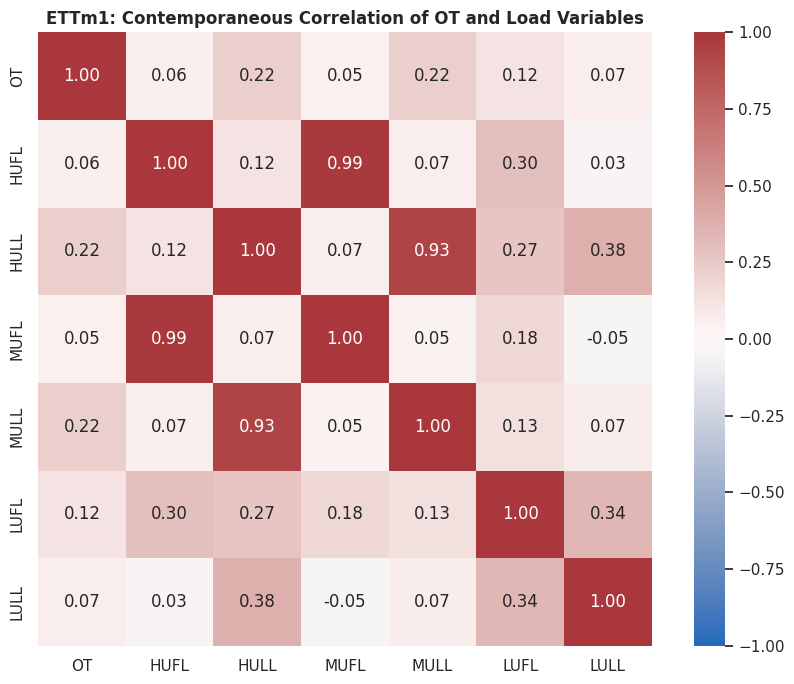

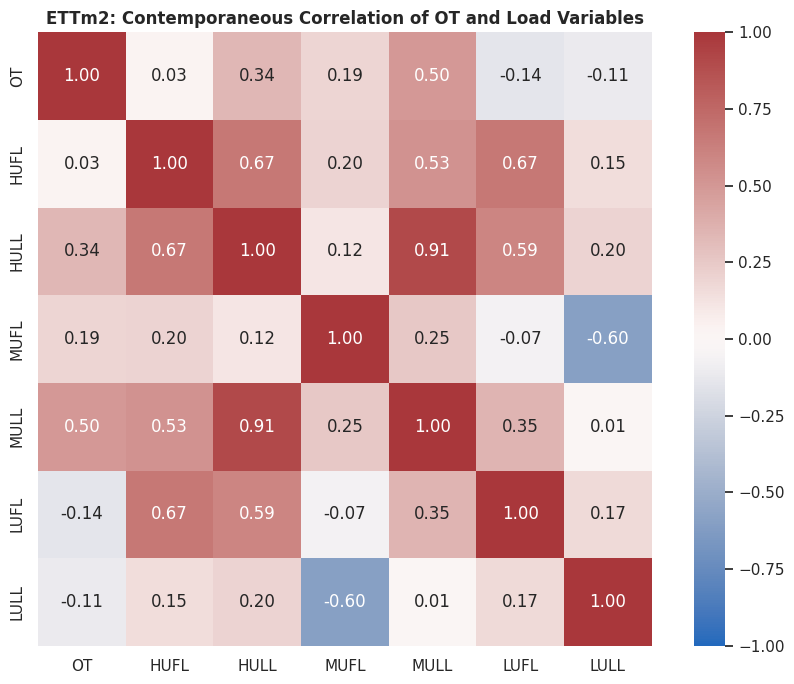

In [6]:
heatmap_figures = {}
for dataset_name, correlation_matrix in correlation_matrices.items():
    fig, ax = correlation_heatmap(
        correlation_matrix,
        title=f"{dataset_name}: Contemporaneous Correlation of OT and Load Variables",
        annot=True,
        vmin=-1,
        vmax=1,
        fmt=".2f",
        cmap="vlag",
    )
    heatmap_figures[dataset_name] = fig
    plt.show()

## 7. ヒートマップ画像と相関行列の保存

PNGとCSVを共通のEDA出力フォルダーへ保存します。ファイル名にはデータセット名を含め、既存のETTh1成果物とは別ファイルにします。

In [7]:
for dataset_name, fig in heatmap_figures.items():
    figure_path = FIGURE_DIR / f"{dataset_name.lower()}_correlation_heatmap.png"
    table_path = TABLE_DIR / f"{dataset_name.lower()}_correlation_matrix.csv"
    fig.savefig(figure_path, dpi=160, bbox_inches="tight")
    correlation_matrices[dataset_name].to_csv(table_path, index=True)
    print(f"{dataset_name}: saved {figure_path} and {table_path}")
    plt.close(fig)

print("完了したデータセット:", DATASET_NAMES)
print("出力先:", OUTPUT_DIR)

ETTh2: saved /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output/figures/etth2_correlation_heatmap.png and /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output/tables/etth2_correlation_matrix.csv
ETTm1: saved /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output/figures/ettm1_correlation_heatmap.png and /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output/tables/ettm1_correlation_matrix.csv
ETTm2: saved /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output/figures/ettm2_correlation_heatmap.png and /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output/tables/ettm2_correlation_matrix.csv
完了したデータセット: ['ETTh2', 'ETTm1', 'ETTm2']
出力先: /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output
